# Project description

In [29]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Flatten, Dense, Input, Masking, MultiHeadAttention, LayerNormalization, Add, Concatenate, Activation, Dropout
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import (EarlyStopping,ReduceLROnPlateau,)
from keras import ops

import matplotlib.pyplot as plt

In [30]:
df = pd.DataFrame({'pActive': [0.7, 0.2], 'popularity': [0.1, 0.4]})
df

,pActive,popularity
0,0.7,0.1
1,0.2,0.4


Consider a simplified model for the election in the NPOS cryptocurrency environment. A nominator can select up to 16 different validators. Each validator has a probability to become active called $pActive$. Then the nominator will get assign to one of the selected active validators in such a way to distribute stakes (money) between validators evenly. Therefore the more popular validator is, the lower probability to be assigned to them.

Example:

With two validators having $pActive$ 0.7 and 0.2 and $popularity$ 0.1 and 0.4 respectively there are 4 possible sceanrios:

 - no validators being active p = (1-0.7) * (1-0.2) = 0.24
 - just validator A p = 0.7 * (1-0.2) = 0.56
 - just validator B p = (1-0.7) * 0.2 = 0.06
 - both validators active p = 0.7 * 0.2 = 0.14

In the first scenario there are no candidates so nobody is assigned. In the second and third case there is just once candidate so with 100% probability she/he wins. The last scenario is the most complex and we have to account for popularity and validator A has 20% chances of wining and B 80%. Combining all scenarios

 - validator A: 0.56 * 100% + 0.14 * 20% = 58.8%
 - validator B: 0.06 * 100% + 0.14 * 80% = 17.2%

We can write a function to calculate it


In [31]:
def getProbability(df):
    combinations = np.indices((2,) * len(df)).reshape(len(df), -1).T.astype(int)
    p = np.maximum((1-combinations)*(1-df.pActive.values), (combinations*df.pActive.values)).prod(1)
    prob = (combinations * df.popularity.values)[1:] / (combinations * df.popularity.values).sum(1).reshape((-1,1))[1:]
    x=(p.reshape((-1,1))[1:] * prob)

    return x.sum(axis=0)

In [32]:
getProbability(df)

array([0.588, 0.172])

In [33]:
np.random.seed(44)
df = pd.DataFrame({'pActive': np.random.rand(23), 'popularity': np.random.rand(23)})
df

,pActive,popularity
0,0.834842,0.873863
1,0.104796,0.258450
2,0.744640,0.664851
3,0.360501,0.862674
4,0.359311,0.148848
5,0.609238,0.562950
6,0.393780,0.159155
7,0.409073,0.172895
8,0.509902,0.104023
9,0.710148,0.202938


In [34]:
getProbability(df)

array([0.12346936, 0.00453064, 0.08349038, 0.04904437, 0.00916577,
       0.05735424, 0.01073811, 0.01210526, 0.00916428, 0.02485904,
       0.07598179, 0.05837941, 0.06652927, 0.01407193, 0.01359698,
       0.08574232, 0.00968469, 0.1074852 , 0.00813592, 0.02911976,
       0.07661866, 0.01784639, 0.05288623])

It might take longer when more candidates are considered. Imagine you have to solve an optimization problem where this function will be executed millions of times thus we want to make it faster.

Your task is to create a neural network estimating function $getProbability$, while being much faster. You can assume the maximum number of validators is 16 and the minimal is 1. $pActive$ is in range from 0 to 1 $popularity$ is greater than 0 without an upper limit. Keep in mind it's possible no validator will be active (scenario 1 in the example above).
Try to avoide using heavy pre- and post-processing (do not put a whole logic of the function there) and do as much computations as possible inside the neural network


Send your result by the end of 25th October on eKursy, provide code with a report or a notebook and results being a .csv file with columns ID (keys of `test_set`) and then val_1 - val_16 (vector of 16 probabilities).


In [35]:
np.random.seed(44)
test_set = {}
for i in range(2, 17):
  for case in range(100):
    test_set[f"{i}_{case}"] =  pd.DataFrame({'pActive': np.random.rand(i), 'popularity': np.random.rand(i)})

# Solution

I use a simple Sequential model with the State of the Art Adam optimizer. Each input contains 16 pairs of features, which are flattened into a 32-element vector. Three hidden dense layers with 256, 128, and 64 neurons use ReLU activations to learn nonlinear relationships. Each hidden layer is followed by dropout with a rate of 0.05 to help reduce overfitting. The final softmax layer predicts 16 validator probabilities and the probability that nobody is assigned.

I selected this architecture for its simplicity.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 17)             │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,705 (198.07 KB)

 Trainable params: 50,705 (198.07 KB)

 Non-trainable params: 0 (0.00 B)

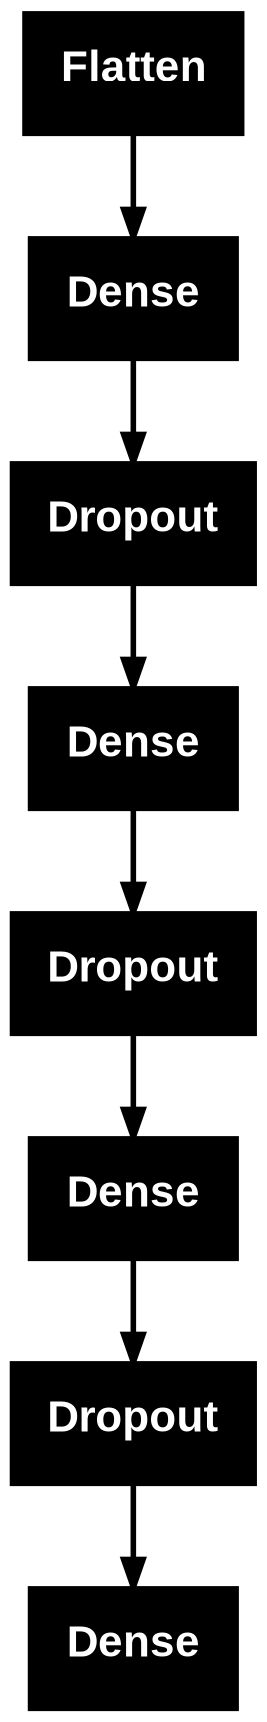

In [36]:
model = Sequential()
model.add(Input(shape=(16,2)))
model.add(Flatten())
model.add(Dense(256, activation="relu"))
model.add(Dropout(0.05))
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.05))
model.add(Dense(64, activation="relu"))
model.add(Dropout(0.05))
model.add(Dense(17, activation="softmax"))

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),loss="mse",metrics=["mae"])

model.summary()
plot_model(model)

I generate separate examples for training and validation, covering between 1 and 16 validators.

Popularity values are divided by the largest popularity in each example. This preserves the reference probabilities and makes the inputs independent of their common popularity scale.

Examples with fewer than 16 validators are padded with zeros.

In [37]:
np.random.seed(45)
training_set = {}

for n in range(1, 17):
    for case in range(200):
        training_set[f"{n}_{case}"] = pd.DataFrame({
            "pActive": np.random.uniform(0.0, 1.0, n),
            "popularity": 10.0 ** np.random.uniform(-2, 2, n),
        })

items = list(training_set.items())

np.random.seed(44)
idx = np.random.permutation(len(items))
split_point = int(0.8 * len(items))

x_train_dict = dict([items[i] for i in idx[:split_point]])
x_test_dict = dict([items[i] for i in idx[split_point:]])

X_train = np.zeros((len(x_train_dict), 16, 2), dtype="float32")
y_train = np.zeros((len(x_train_dict), 17), dtype="float32")

for i, (key, df) in enumerate(x_train_dict.items()):
    n = len(df)

    values = df[["pActive", "popularity"]].to_numpy(
        dtype="float64", copy=True
    )
    values[:, 1] /= values[:, 1].max() #normilization of popularity
    X_train[i, :n] = values

    y_train[i, :n] = getProbability(df)
    y_train[i, 16] = np.prod(1.0 - df["pActive"].to_numpy())

X_test = np.zeros((len(x_test_dict), 16, 2), dtype="float32")
y_test = np.zeros((len(x_test_dict), 17), dtype="float32")

for i, (key, df) in enumerate(x_test_dict.items()):
    n = len(df)

    values = df[["pActive", "popularity"]].to_numpy(
        dtype="float64", copy=True
    )
    values[:, 1] /= values[:, 1].max()
    X_test[i, :n] = values

    y_test[i, :n] = getProbability(df)
    y_test[i, 16] = np.prod(1.0 - df["pActive"].to_numpy())

The model is trained for a maximum of 1,000 epochs.

Early stopping monitors validation MAE and restores the selected weights when improvement stops. The learning rate is reduced when validation MAE plateaus.

In [38]:
early = EarlyStopping(
    monitor="val_mae",
    mode="min",
    min_delta=1e-5,
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

reduce = ReduceLROnPlateau(
    monitor="val_mae",
    mode="min",
    min_delta=1e-5,
    factor=0.5,
    patience=4,
    min_lr=1e-4,
    verbose=1,
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=1000,
    batch_size=32,
    callbacks=[reduce, early],
    verbose=2,
)

Epoch 1/1000
80/80 - 2s - 25ms/step - loss: 0.0122 - mae: 0.0615 - val_loss: 0.0065 - val_mae: 0.0417 - learning_rate: 0.0010
Epoch 2/1000
80/80 - 0s - 4ms/step - loss: 0.0057 - mae: 0.0396 - val_loss: 0.0042 - val_mae: 0.0334 - learning_rate: 0.0010
Epoch 3/1000
80/80 - 0s - 4ms/step - loss: 0.0044 - mae: 0.0348 - val_loss: 0.0035 - val_mae: 0.0305 - learning_rate: 0.0010
Epoch 4/1000
80/80 - 0s - 4ms/step - loss: 0.0038 - mae: 0.0327 - val_loss: 0.0033 - val_mae: 0.0291 - learning_rate: 0.0010
Epoch 5/1000
80/80 - 0s - 4ms/step - loss: 0.0034 - mae: 0.0311 - val_loss: 0.0028 - val_mae: 0.0276 - learning_rate: 0.0010
Epoch 6/1000
80/80 - 1s - 6ms/step - loss: 0.0031 - mae: 0.0294 - val_loss: 0.0029 - val_mae: 0.0280 - learning_rate: 0.0010
Epoch 7/1000
80/80 - 1s - 7ms/step - loss: 0.0029 - mae: 0.0288 - val_loss: 0.0026 - val_mae: 0.0264 - learning_rate: 0.0010
Epoch 8/1000
80/80 - 1s - 9ms/step - loss: 0.0027 - mae: 0.0277 - val_loss: 0.0025 - val_mae: 0.0255 - learning_rate: 0.0010

We plot the final results to confirm that our learning went right.

The graphs show training and validation MSE and MAE over successive epochs.

Validation MAE can be lower than training MAE because dropout is active during training and disabled during validation.

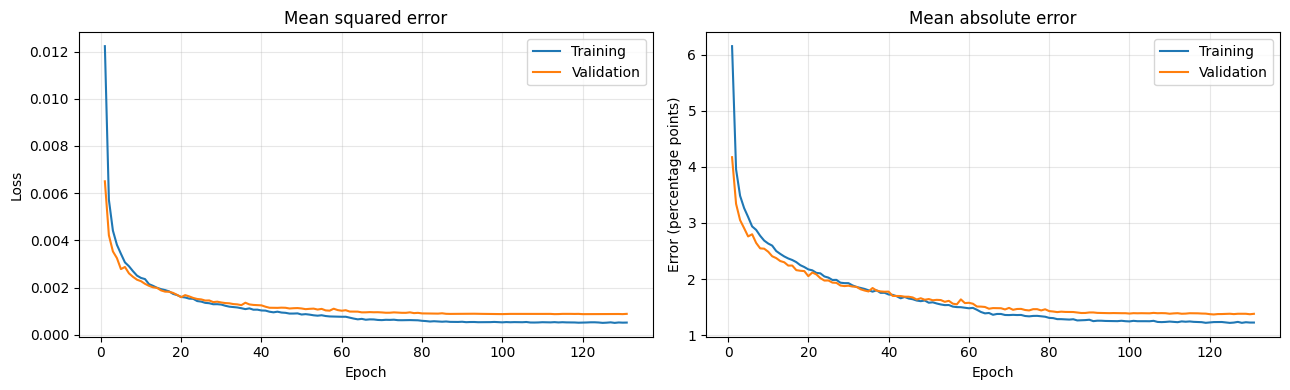

In [39]:
epochs = np.arange(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, history.history["loss"], label="Training")
axes[0].plot(epochs, history.history["val_loss"], label="Validation")
axes[0].set_title("Mean squared error")
axes[0].set_ylabel("Loss")

axes[1].plot(
    epochs, np.array(history.history["mae"]) * 100,
    label="Training"
)
axes[1].plot(
    epochs, np.array(history.history["val_mae"]) * 100,
    label="Validation"
)
axes[1].set_title("Mean absolute error")
axes[1].set_ylabel("Error (percentage points)")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Checking example from the exercise description.

In [40]:
df = pd.DataFrame({
    "pActive": [0.7, 0.2],
    "popularity": [0.1, 0.4],
})

values = df[["pActive", "popularity"]].to_numpy(
    dtype="float64", copy=True
)
values[:, 1] /= values[:, 1].max()

X = np.zeros((1, 16, 2), dtype="float32")
X[0, :len(df)] = values

y_pred = model.predict(X, verbose=0)
y_pred[:, :16] *= X[:, :, 1] > 0
y_pred /= y_pred.sum(axis=1, keepdims=True)

print("Reference probabilities:", getProbability(df).round(4))
print("Network probabilities:", y_pred[0, :2].round(4))

Reference probabilities: [0.588 0.172]
Network probabilities: [0.6125 0.1545]


This benchmark compares the deterministic function with warmed, compiled neural-network for one example containing 16 validators.

In [41]:
from timeit import timeit

rng = np.random.default_rng(44)

df = pd.DataFrame({
    "pActive": rng.random(16),
    "popularity": rng.uniform(0.01, 1.0, 16),
})

values = df[["pActive", "popularity"]].to_numpy(
    dtype="float64", copy=True
)
values[:, 1] /= values[:, 1].max()

X = values.astype("float32")[None, :, :]

predict = tf.function(lambda x: model(x, training=False))
predict(X).numpy()

t1 = timeit(lambda: getProbability(df), number=100) / 100
t2 = timeit(lambda: predict(X).numpy(), number=100) / 100

print(f"Deterministic: {t1 * 1000:.4f} ms")
print(f"Network:      {t2 * 1000:.4f} ms")
print(f"Speedup:      {t1 / t2:.2f}x")

Deterministic: 44.8801 ms
Network:      0.7257 ms
Speedup:      61.84x


## Generating the CSV file

I use the trained model to generate predictions for all previously given 1500 examples.

Across the 13,500 real validator probabilities, the MAE is ~2.59 percentage points.

In [42]:
ids = list(test_set)
X_csv = np.zeros((len(ids), 16, 2), dtype="float32")

for i, key in enumerate(ids):
    df = test_set[key]
    n = len(df)

    values = df[["pActive", "popularity"]].to_numpy(
        dtype="float64", copy=True
    )
    values[:, 1] /= values[:, 1].max()

    X_csv[i, :n] = values

predictions = model.predict(X_csv, verbose=0)
predictions[:, :16] *= X_csv[:, :, 1] > 0
predictions /= predictions.sum(axis=1, keepdims=True)

results = pd.DataFrame(
    predictions[:, :16],
    columns=[f"val_{i}" for i in range(1, 17)],
)
results.insert(0, "ID", ids)
results.to_csv("results.csv", index=False)

from google.colab import files
files.download("results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Summary and Report

In this notebook, I analyzed the provided problem, prepared the data, created and trained a neural network, and analyzed the results.

The problem involves deterministic probability calculations that become computationally expensive as the number of validators increases, because the reference function considers \(2^N\) activation scenarios. Neural networks can be trained on correctly calculated examples to approximate these probabilities more quickly.

During my work, I first used the provided `getProbability` function to generate target probabilities. I normalized popularity values and padded unused validator positions with zeros. I then divided the generated examples into training and validation sets. I trained a simple neural network with learning-rate reduction and early stopping. Flattening converted the input into a vector, while dropout helped reduce overfitting. Early stopping restored the selected model weights, and the resulting loss and error are shown above.

After comparing calculation times, I found that the neural network was faster for the tested 16-validator example. For smaller examples, deterministic calculations may be more efficient. Neural networks can therefore be useful for larger examples when some approximation error is acceptable.

I attach to this report predictions for all examples provided at the beginning of the notebook.